In [2]:
import pandas as pd
from pandas.api.types import is_numeric_dtype
import numpy as np
import matplotlib.pyplot as plt

print("Exoplanet analysis environment is ready!")

Exoplanet analysis environment is ready!


---
First, we read the dataset obtained from the NASA exoplanet archive into a pandas dataframe.

In [3]:
df = pd.read_csv("NASA_exoplanet_archive.csv", comment = "#")
df.head()

,pl_name,hostname,default_flag,sy_snum,sy_pnum,discoverymethod,disc_year,disc_facility,soltype,pl_controv_flag,...,sy_vmagerr2,sy_kmag,sy_kmagerr1,sy_kmagerr2,sy_gaiamag,sy_gaiamagerr1,sy_gaiamagerr2,rowupdate,pl_pubdate,releasedate
0,11 Com b,11 Com,0,2,1,Radial Velocity,2007,Xinglong Station,Published Confirmed,0,...,-0.023,2.282,0.346,-0.346,4.44038,0.003848,-0.003848,2014-07-23,2011-08,2014-07-23
1,11 Com b,11 Com,1,2,1,Radial Velocity,2007,Xinglong Station,Published Confirmed,0,...,-0.023,2.282,0.346,-0.346,4.44038,0.003848,-0.003848,2023-09-19,2023-12,2023-09-19
2,11 Com b,11 Com,0,2,1,Radial Velocity,2007,Xinglong Station,Published Confirmed,0,...,-0.023,2.282,0.346,-0.346,4.44038,0.003848,-0.003848,2014-05-14,2008-01,2014-05-14
3,11 UMi b,11 UMi,1,1,1,Radial Velocity,2009,Thueringer Landessternwarte Tautenburg,Published Confirmed,0,...,-0.005,1.939,0.270,-0.270,4.56216,0.003903,-0.003903,2018-09-04,2017-03,2018-09-06
4,11 UMi b,11 UMi,0,1,1,Radial Velocity,2009,Thueringer Landessternwarte Tautenburg,Published Confirmed,0,...,-0.005,1.939,0.270,-0.270,4.56216,0.003903,-0.003903,2018-04-25,2011-08,2014-07-23


In [8]:
df.describe()

,default_flag,sy_snum,sy_pnum,disc_year,pl_controv_flag,pl_orbper,pl_orbpererr1,pl_orbpererr2,pl_orbperlim,pl_orbsmax,...,sy_disterr2,sy_vmag,sy_vmagerr1,sy_vmagerr2,sy_kmag,sy_kmagerr1,sy_kmagerr2,sy_gaiamag,sy_gaiamagerr1,sy_gaiamagerr2
count,40106.000000,40106.000000,40106.000000,40106.000000,40106.000000,3.669800e+04,3.498100e+04,3.498000e+04,36698.000000,22373.000000,...,38348.000000,39216.000000,39203.000000,39202.000000,39214.000000,38972.000000,38972.000000,38915.000000,38915.000000,38915.000000
mean,0.158430,1.086496,1.918167,2015.665312,0.004164,1.193083e+04,1.379194e+04,-3.251259e+03,-0.000245,4.744332,...,-38.697674,13.502720,0.114776,-0.115347,11.470668,0.034969,-0.034488,13.263767,0.000524,-0.000524
std,0.365148,0.312518,1.241065,4.167520,0.064395,2.099699e+06,2.513120e+06,5.359078e+05,0.020216,179.376108,...,184.863998,2.463708,0.149841,0.178501,2.371869,0.183536,0.174973,2.402750,0.001090,0.001090
min,0.000000,1.000000,1.000000,1992.000000,0.000000,9.070629e-02,0.000000e+00,-1.000000e+08,-1.000000,0.004400,...,-2900.000000,0.872000,0.001000,-12.270000,-3.044000,0.011000,-11.140000,2.364310,0.000112,-0.063232
25%,0.000000,1.000000,1.000000,2014.000000,0.000000,4.362744e+00,8.032400e-06,-2.013000e-04,0.000000,0.054540,...,-20.172000,12.429000,0.046000,-0.137000,10.549000,0.020000,-0.033000,12.217900,0.000254,-0.000508
50%,0.000000,1.000000,1.000000,2016.000000,0.000000,1.030400e+01,3.829000e-05,-3.834916e-05,0.000000,0.101500,...,-7.170000,14.126000,0.092000,-0.092000,12.205000,0.024000,-0.024000,13.918000,0.000353,-0.000353
75%,0.000000,1.000000,2.000000,2016.000000,0.000000,2.662946e+01,2.020000e-04,-8.060000e-06,0.000000,0.223500,...,-1.867000,15.240000,0.137000,-0.046000,13.135000,0.033000,-0.020000,15.015100,0.000508,-0.000254
max,1.000000,4.000000,8.000000,2026.000000,1.000000,4.020000e+08,4.700000e+08,0.000000e+00,1.000000,19000.000000,...,2700.000000,45.340000,11.000000,-0.001000,35.330000,9.995000,-0.011000,20.186100,0.063232,-0.000112


In [9]:
df.shape

(40106, 92)

---
The dataset has two variables that can help with data cleaning and data integrity: default_flag and pl_controv_flag. The data as it stands contains multiple entries for each planet potentially due to multiple detections using different detection methods - e.g.: transit, radial velocity, etc - which could skew any analysis. The default_flag variable indicates which entry for each planet has been selected by NASA to represent the default set of values for that planet. For this analysis, we will be using these default entries. The pl_controv_flag variable indicates whether the entry has been flagged by NASA as being controversial. To avoid outliers that could potentially skew the data, we will remove these controversial entries.

In [4]:
df_clean = df[(df["default_flag"] == 1) & (df["pl_controv_flag"] == 0)]

In [23]:
print("Original Dataset:")
print(" Rows:", len(df))
print(" Columns:", len(df.columns))

print(" Missing planet names:", df["pl_name"].isna().sum())
print(" Duplicate planet names:", df["pl_name"].duplicated().sum())
print(" Unique planets:", df["pl_name"].nunique())

print("\n")

print("New Dataset:")
print(" Rows:", len(df_clean))
print(" Columns:", len(df_clean.columns))
print(" Missing planet names:", df_clean["pl_name"].isna().sum())
print(" Duplicate planet names:", df_clean["pl_name"].duplicated().sum())
print(" Unique planets:", df_clean["pl_name"].nunique())

Original Dataset:
 Rows: 40106
 Columns: 92
 Missing planet names: 0
 Duplicate planet names: 33752
 Unique planets: 6354


New Dataset:
 Rows: 6296
 Columns: 92
 Missing planet names: 0
 Duplicate planet names: 0
 Unique planets: 6296


In [34]:
main_columns = [
    "pl_name", "disc_year", "discoverymethod", "pl_bmasse",
    "pl_rade", "pl_orbper", "pl_orbsmax"
]

print(df_clean[important_columns].dtypes)

pl_name                str
disc_year            int64
discoverymethod        str
pl_bmasse          float64
pl_rade            float64
pl_orbper          float64
pl_orbsmax         float64
dtype: object


In [43]:
for column in main_columns:
    if is_numeric_dtype(df_clean[column]):
        print(f"\n{column}")
        print("Missing:", df_clean[column].isna().sum())
        print("Zero or negative:", (df_clean[column] <= 0).sum())
        print("Minimum:", df_clean[column].min())
        print("Maximum:", df_clean[column].max())


disc_year
Missing: 0
Zero or negative: 0
Minimum: 1992
Maximum: 2026

pl_bmasse
Missing: 3196
Zero or negative: 0
Minimum: 0.02
Maximum: 9534.85221

pl_rade
Missing: 1573
Zero or negative: 0
Minimum: 0.3098
Maximum: 87.20586985

pl_orbper
Missing: 363
Zero or negative: 0
Minimum: 0.090706293
Maximum: 8040000.0

pl_orbsmax
Missing: 2428
Zero or negative: 0
Minimum: 0.0044
Maximum: 19000.0


In [44]:
for column in main_columns:
    if is_numeric_dtype(df_clean[column]):
        print(f"\nLargest values for {column}:")
        
        print(
            df_clean.nlargest(5, column)[
                ["pl_name", "hostname", "discoverymethod", column]
                ].to_string(index=False)
        )


Largest values for disc_year:
 pl_name hostname discoverymethod  disc_year
DMPP-2 c   DMPP-2 Radial Velocity       2026
DMPP-2 d   DMPP-2 Radial Velocity       2026
DMPP-6 b   DMPP-6 Radial Velocity       2026
DMPP-6 c   DMPP-6 Radial Velocity       2026
DMPP-7 b   DMPP-7 Radial Velocity       2026

Largest values for pl_bmasse:
                  pl_name                hostname discoverymethod   pl_bmasse
2MASS J22501512+2325342 b 2MASS J22501512+2325342         Imaging 9534.852210
             CD-35 2722 b              CD-35 2722         Imaging 9375.938007
              Luhman 16 b             Luhman 16 A         Imaging 9344.155166
              HD 188641 b               HD 188641 Radial Velocity 9333.031172
     KMT-2018-BLG-0885L b      KMT-2018-BLG-0885L    Microlensing 9217.023803

Largest values for pl_rade:
      pl_name    hostname discoverymethod  pl_rade
  V2376 Ori b   V2376 Ori         Imaging 87.20587
     GQ Lup b      GQ Lup         Imaging 33.60000
 Kepler-297 d  Kep

In [33]:
df_clean["discoverymethod"].value_counts()

discoverymethod
Transit                          4681
Radial Velocity                  1167
Microlensing                      283
Imaging                            94
Transit Timing Variations          42
Eclipse Timing Variations           8
Pulsar Timing                       8
Astrometry                          6
Orbital Brightness Modulation       4
Pulsation Timing Variations         2
Disk Kinematics                     1
Name: count, dtype: int64

In [45]:
df_clean[main_columns].describe()

,disc_year,pl_bmasse,pl_rade,pl_orbper,pl_orbsmax
count,6296.000000,3100.000000,4723.000000,5.933000e+03,3868.000000
mean,2017.296696,767.846275,4.481998,4.360697e+03,20.337670
std,5.124809,1501.668014,4.831468,1.615207e+05,408.033621
min,1992.000000,0.020000,0.309800,9.070629e-02,0.004400
25%,2014.000000,12.210500,1.640000,4.302149e+00,0.053200
50%,2016.000000,170.996270,2.467420,1.064387e+01,0.113750
75%,2021.000000,692.869400,4.184500,3.763271e+01,0.803250
max,2026.000000,9534.852210,87.205870,8.040000e+06,19000.000000


In [6]:
mass_radius = df_clean.dropna(subset = ["pl_bmasse", "pl_rade"]).copy()

period_radius = df_clean.dropna(subset = ["pl_orbper", "pl_bmasse"]).copy()

period_mass = df_clean.dropna(subset = ["pl_orbper", "pl_bmasse"]).copy()

print("Mass and radius:", len(mass_radius))
print("Period and radius:", len(period_radius))
print("Period and mass:", len(period_mass))

Mass and radius: 1544
Period and radius: 2753
Period and mass: 2753


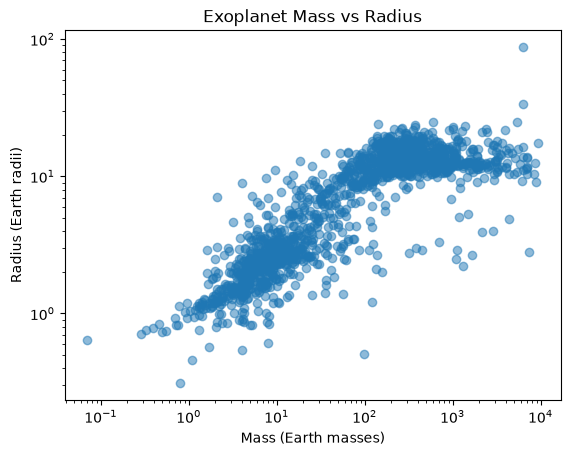

In [47]:
plt.scatter(
    mass_radius["pl_bmasse"],
    mass_radius["pl_rade"],
    alpha = 0.5
)

plt.xscale("log")
plt.yscale("log")

plt.xlabel("Mass (Earth masses)")
plt.ylabel("Radius (Earth radii)")
plt.title("Exoplanet Mass vs Radius")

plt.show()

In [48]:
correlation = mass_radius["pl_bmasse"].corr(mass_radius["pl_rade"])

log_correlation = np.log10(mass_radius["pl_bmasse"]).corr(np.log10(mass_radius["pl_rade"]))

print("Mass-radius correlation:", correlation)
print("Logarithmic mass-radius correlation:", log_correlation)

Mass-radius correlation: 0.3606733670737473
Logarithmic mass-radius correlation: 0.862780477068796


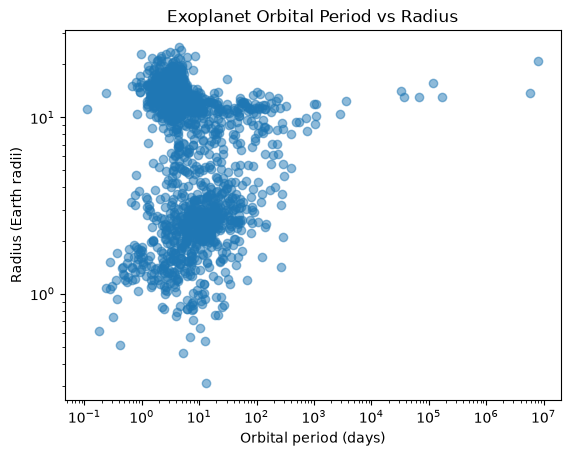

In [49]:
plt.scatter(
    period_radius["pl_orbper"],
    period_radius["pl_rade"],
    alpha = 0.5)

plt.xscale("log")
plt.yscale("log")

plt.xlabel("Orbital period (days)")
plt.ylabel("Radius (Earth radii)")
plt.title("Exoplanet Orbital Period vs Radius")

plt.show()

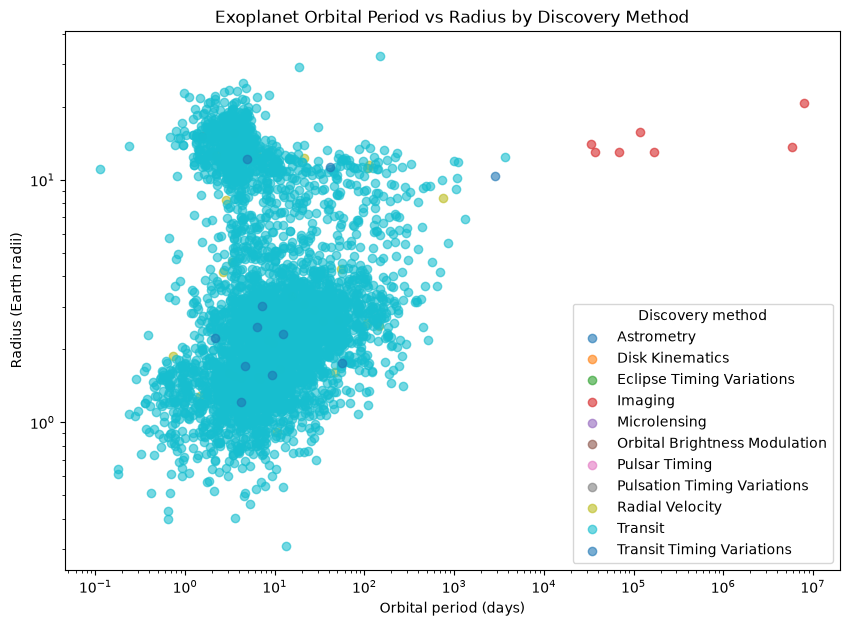

In [19]:
plt.figure(figsize = (10,7))

for method, group in df_clean.groupby("discoverymethod"):
    plt.scatter(
        group["pl_orbper"],
        group["pl_rade"],
        alpha = 0.6,
        label = method
    )

plt.xscale("log")
plt.yscale("log")
plt.xlabel("Orbital period (days)")
plt.ylabel("Radius (Earth radii)")
plt.title("Exoplanet Orbital Period vs Radius by Discovery Method")
plt.legend(title = "Discovery method", loc = "lower right")

plt.show()

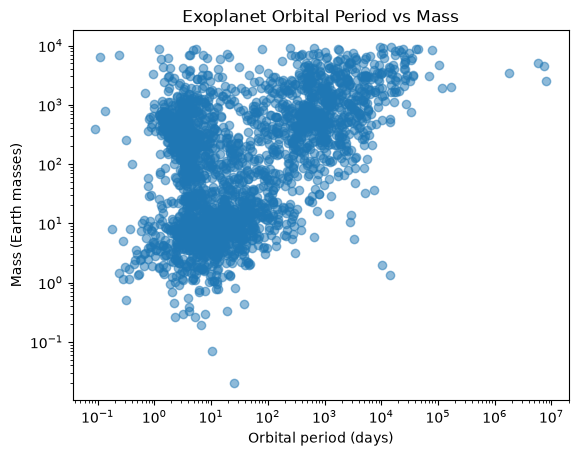

In [50]:
plt.scatter(
    period_mass["pl_orbper"],
    period_mass["pl_bmasse"],
    alpha = 0.5)

plt.xscale("log")
plt.yscale("log")


plt.xlabel("Orbital period (days)")
plt.ylabel("Mass (Earth masses)")
plt.title("Exoplanet Orbital Period vs Mass")

plt.show()

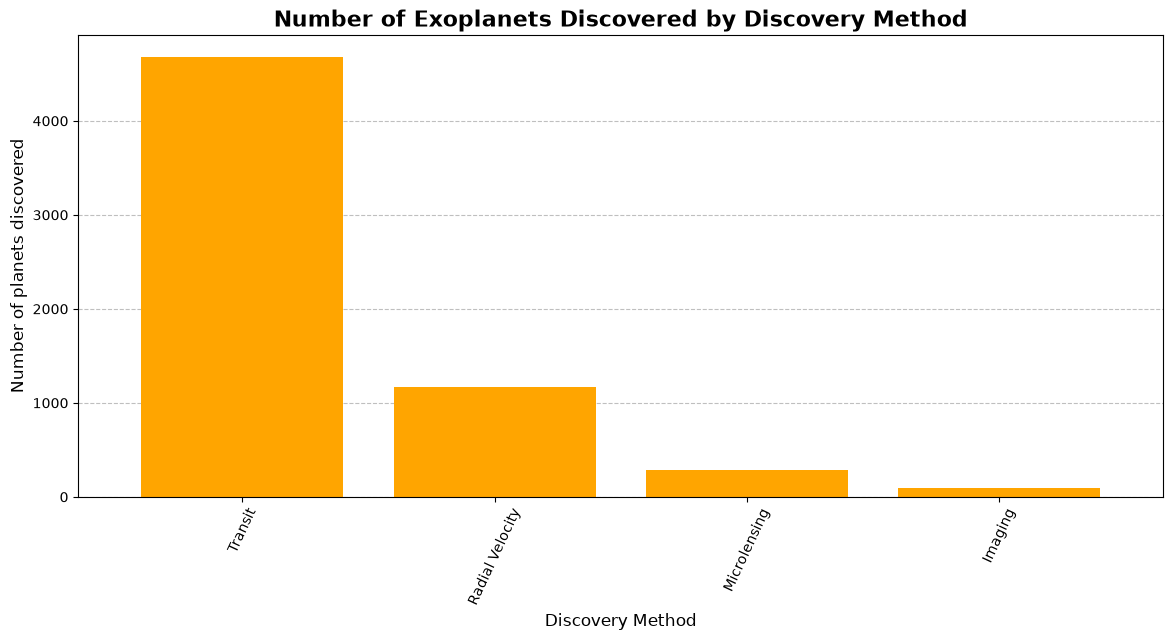

In [15]:
method_counts = df_clean["discoverymethod"].value_counts().head(4)

ax = method_counts.plot(kind = "bar", figsize = (14,6), color = "orange", width = 0.8)

ax.set_xlabel("Discovery Method", fontsize = 12)
ax.set_ylabel("Number of planets discovered", fontsize = 12)

ax.set_title("Number of Exoplanets Discovered by Discovery Method", fontsize = 16, fontweight = "bold")

ax.tick_params(axis = "x", rotation = 65, labelsize = 10)
ax.tick_params(axis = "y", labelsize = 10)

ax.set_axisbelow(True)
ax.grid(axis = "y", linestyle = "--", alpha = 0.8)

plt.show()

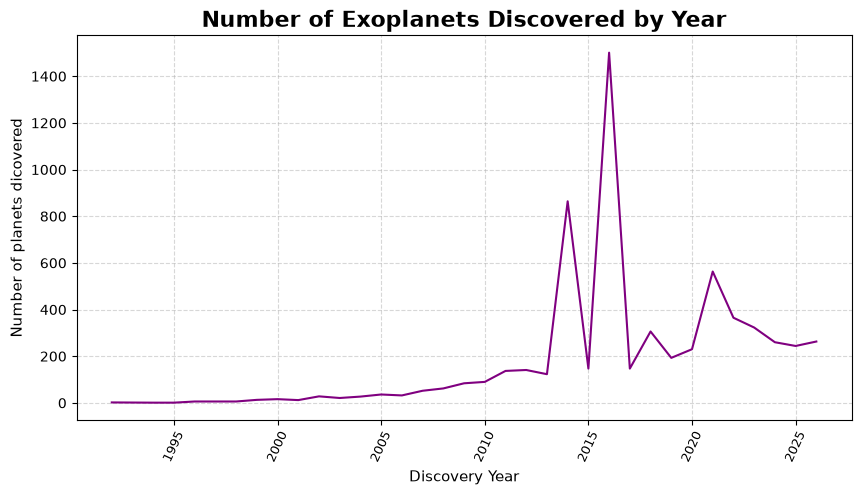

In [52]:
year_counts = df_clean["disc_year"].value_counts().sort_index()

year_counts.plot(kind = "line", figsize = (10,5), color = "purple")

plt.xlabel("Discovery Year", fontsize = 11)
plt.ylabel("Number of planets dicovered", fontsize = 11)
plt.title("Number of Exoplanets Discovered by Year", fontsize = 16, fontweight = "bold")


plt.grid(linestyle = "--", alpha = 0.5)
plt.xticks(rotation = 65, fontsize = 9)
plt.show()

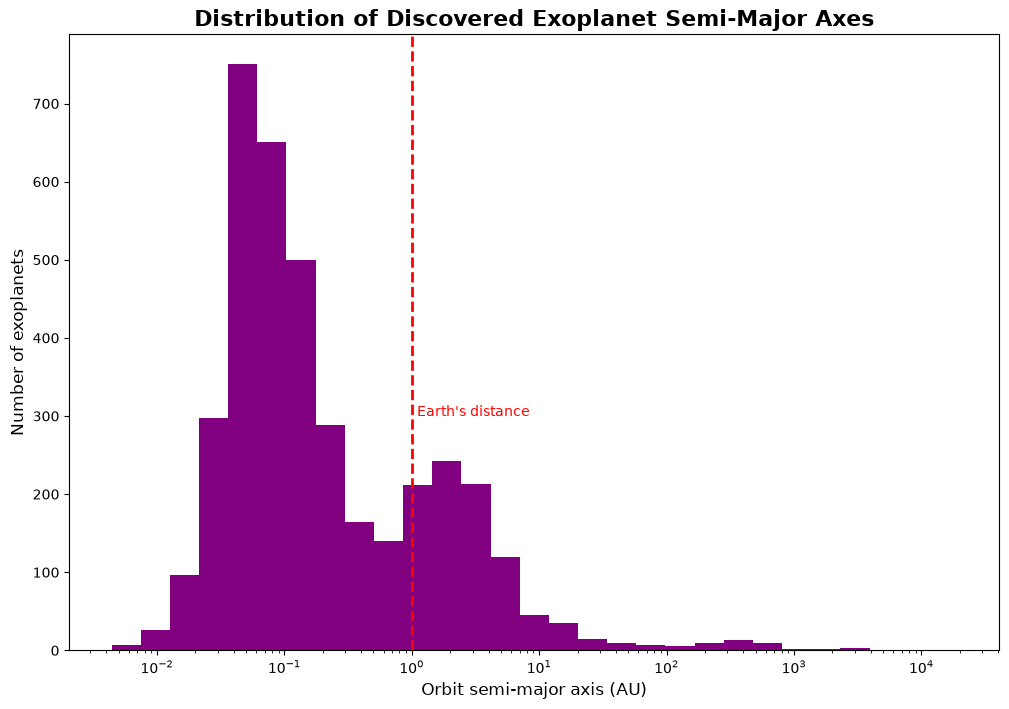

In [53]:
distances = df_clean["pl_orbsmax"].dropna()
distances = distances[distances > 0]
bins = np.logspace(
        np.log10(distances.min()),
        np.log10(distances.max()),
        30
)

plt.figure(figsize = (12,8))

plt.hist(distances, bins = bins, color = "purple")
plt.xscale("log")

plt.axvline(x = 1, color = "red", linewidth = 2, linestyle = "--")
plt.text(1.1, 300, "Earth's distance", color = "red")

plt.xlabel("Orbit semi-major axis (AU)", fontsize = 12)
plt.ylabel("Number of exoplanets", fontsize = 12)
plt.title("Distribution of Discovered Exoplanet Semi-Major Axes", fontsize = 16, fontweight = "bold")

plt.show()

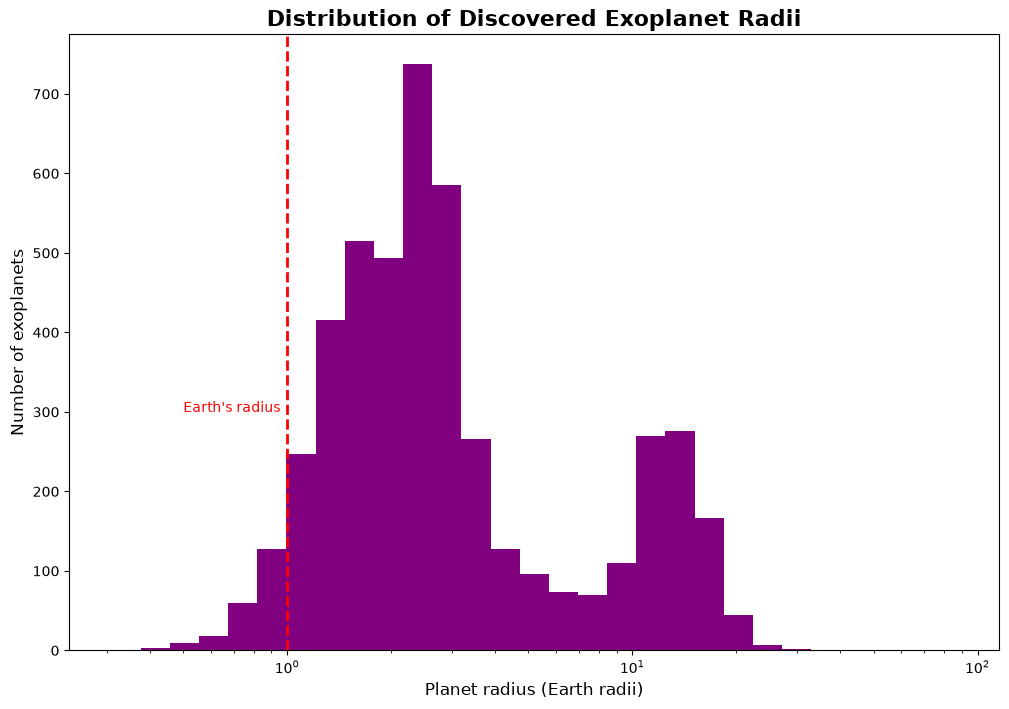

In [54]:
radii = df_clean["pl_rade"].dropna()

bins = np.logspace(
        np.log10(radii.min()),
        np.log10(radii.max()),
        30
)

plt.figure(figsize = (12,8))

plt.hist(radii, bins = bins, color = "purple")
plt.xscale("log")

plt.axvline(x = 1, color = "red", linewidth = 2, linestyle = "--")
plt.text(0.5, 300, "Earth's radius", color = "red")

plt.xlabel("Planet radius (Earth radii)", fontsize = 12)
plt.ylabel("Number of exoplanets", fontsize = 12)
plt.title("Distribution of Discovered Exoplanet Radii", fontsize = 16, fontweight = "bold")

plt.show()

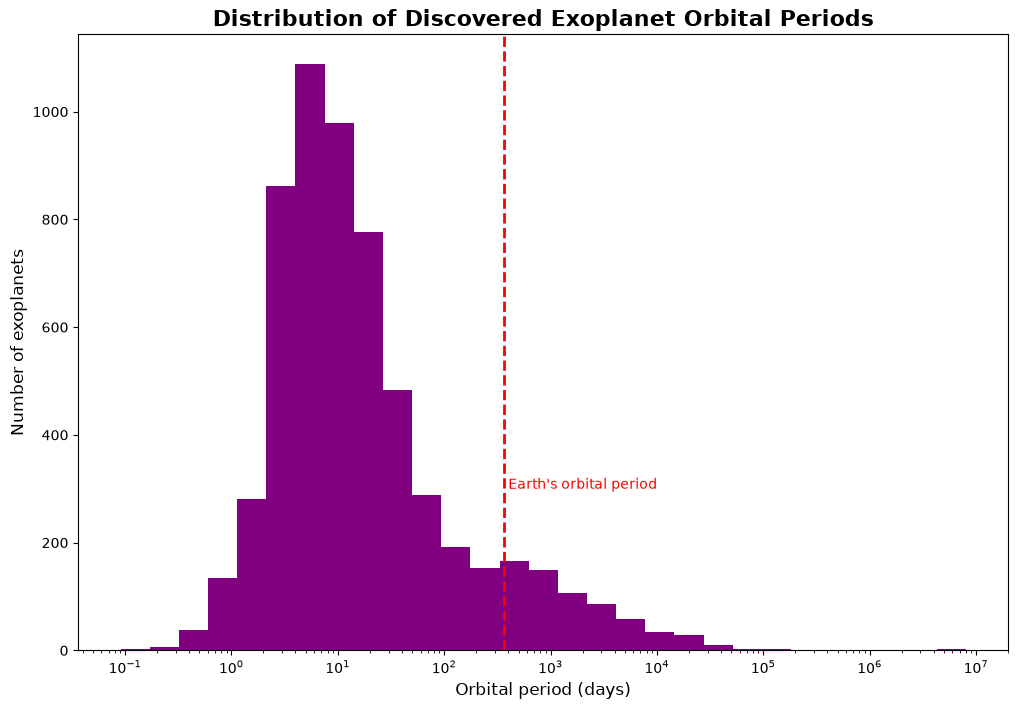

In [55]:
periods = df_clean["pl_orbper"].dropna()

bins = np.logspace(
        np.log10(periods.min()),
        np.log10(periods.max()),
        30
)

plt.figure(figsize = (12,8))

plt.hist(periods, bins = bins, color = "purple")
plt.xscale("log")

plt.axvline(x = 365.25, color = "red", linewidth = 2, linestyle = "--")
plt.text(400, 300, "Earth's orbital period", color = "red")

plt.xlabel("Orbital period (days)", fontsize = 12)
plt.ylabel("Number of exoplanets", fontsize = 12)
plt.title("Distribution of Discovered Exoplanet Orbital Periods", fontsize = 16, fontweight = "bold")

plt.show()

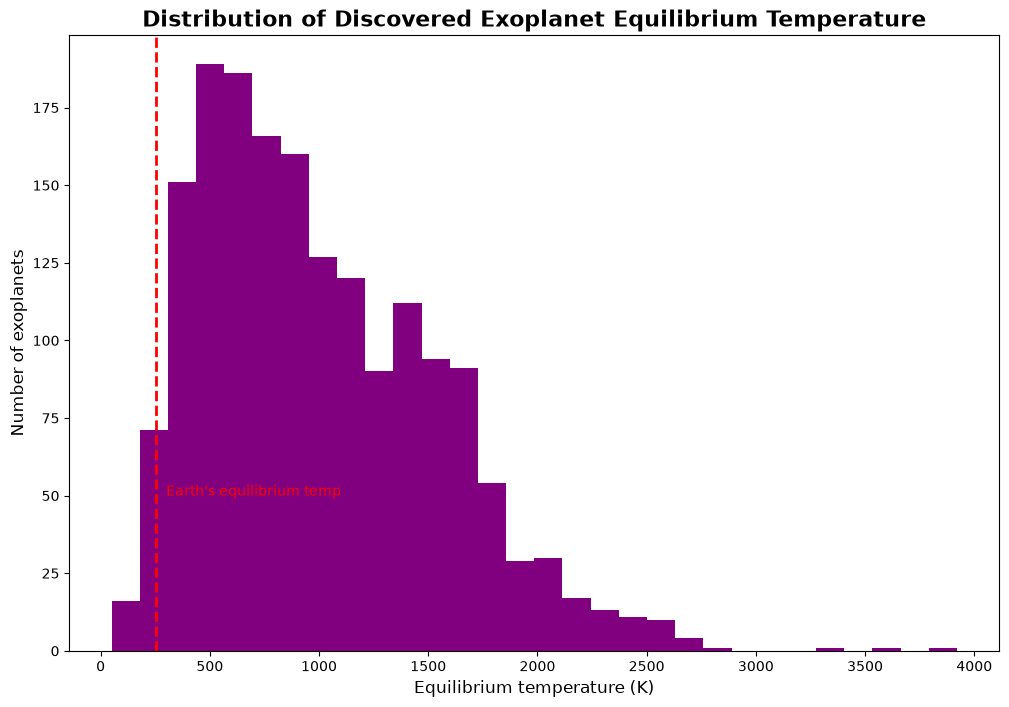

In [56]:
temps = df_clean["pl_eqt"].dropna()

plt.figure(figsize = (12,8))

plt.hist(temps, bins = 30, color = "purple")

plt.axvline(x = 255, color = "red", linewidth = 2, linestyle = "--")
plt.text(300, 50, "Earth's equilibrium temp", color = "red")

plt.xlabel("Equilibrium temperature (K)", fontsize = 12)
plt.ylabel("Number of exoplanets", fontsize = 12)
plt.title("Distribution of Discovered Exoplanet Equilibrium Temperature", fontsize = 16, fontweight = "bold")

plt.show()

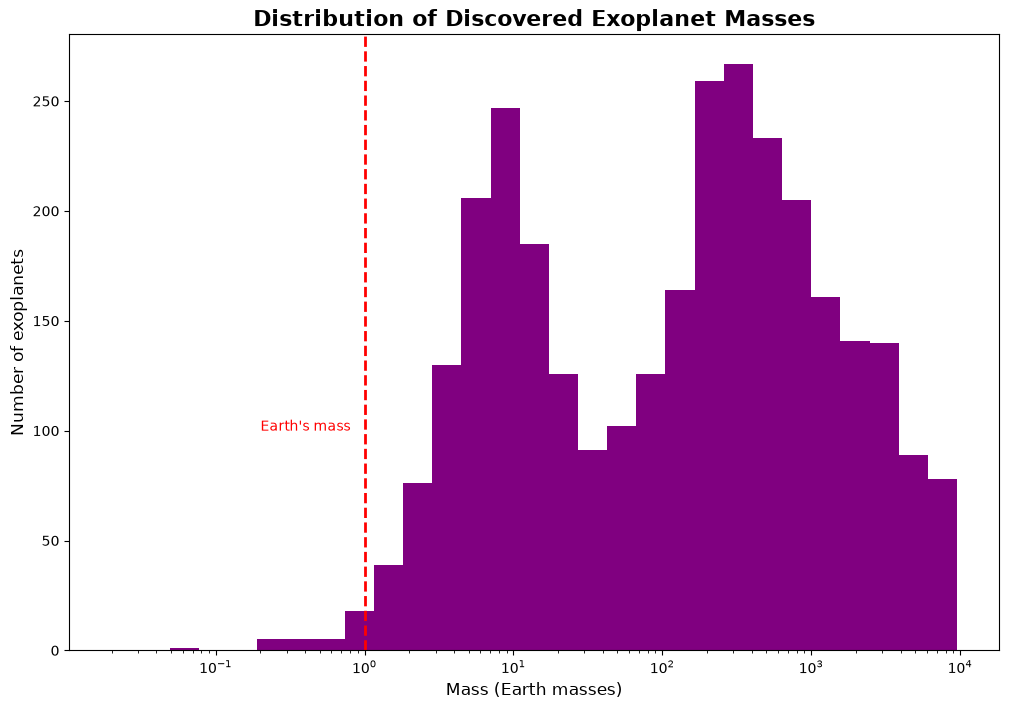

In [57]:
masses = df_clean["pl_bmasse"].dropna()

bins = np.logspace(
        np.log10(masses.min()),
        np.log10(masses.max()),
        30
)

plt.figure(figsize = (12,8))

plt.hist(masses, bins = bins, color = "purple")
plt.xscale("log")

plt.axvline(x = 1, color = "red", linewidth = 2, linestyle = "--")
plt.text(0.2, 100, "Earth's mass", color = "red")

plt.xlabel("Mass (Earth masses)", fontsize = 12)
plt.ylabel("Number of exoplanets", fontsize = 12)
plt.title("Distribution of Discovered Exoplanet Masses", fontsize = 16, fontweight = "bold")

plt.show()

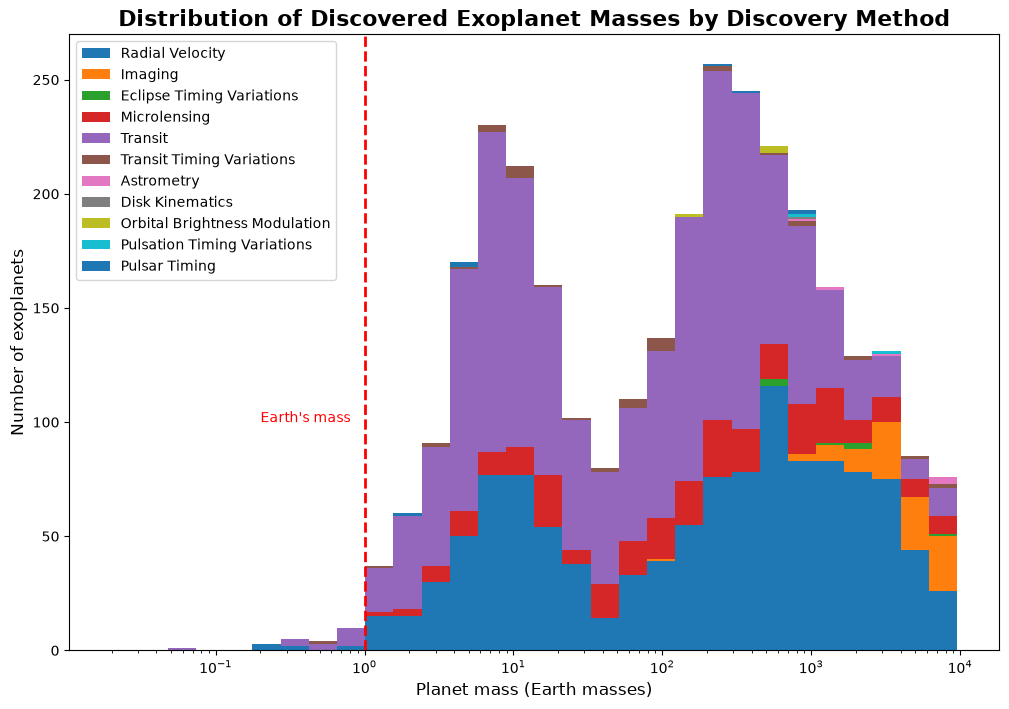

In [58]:
plot_data = []

methods = df_clean["discoverymethod"].dropna().unique()

for method in methods:
    masses = df_clean.loc[
        (df_clean["discoverymethod"] == method),
        "pl_bmasse"
        ].dropna()

    plot_data.append(masses)

bins = np.logspace(
        np.log10(df_clean["pl_bmasse"].min()),
        np.log10(df_clean["pl_bmasse"].max()),
        31
)

plt.figure(figsize = (12,8))

plt.hist(plot_data,
         bins = bins,
         stacked = True,
         label = methods)

plt.xscale("log")

plt.axvline(x = 1, color = "red", linewidth = 2, linestyle = "--")
plt.text(0.2, 100, "Earth's mass", color = "red")

plt.xlabel("Planet mass (Earth masses)", fontsize = 12)
plt.ylabel("Number of exoplanets", fontsize = 12)
plt.title("Distribution of Discovered Exoplanet Masses by Discovery Method", fontsize = 16, fontweight = "bold")
plt.legend()
plt.show()

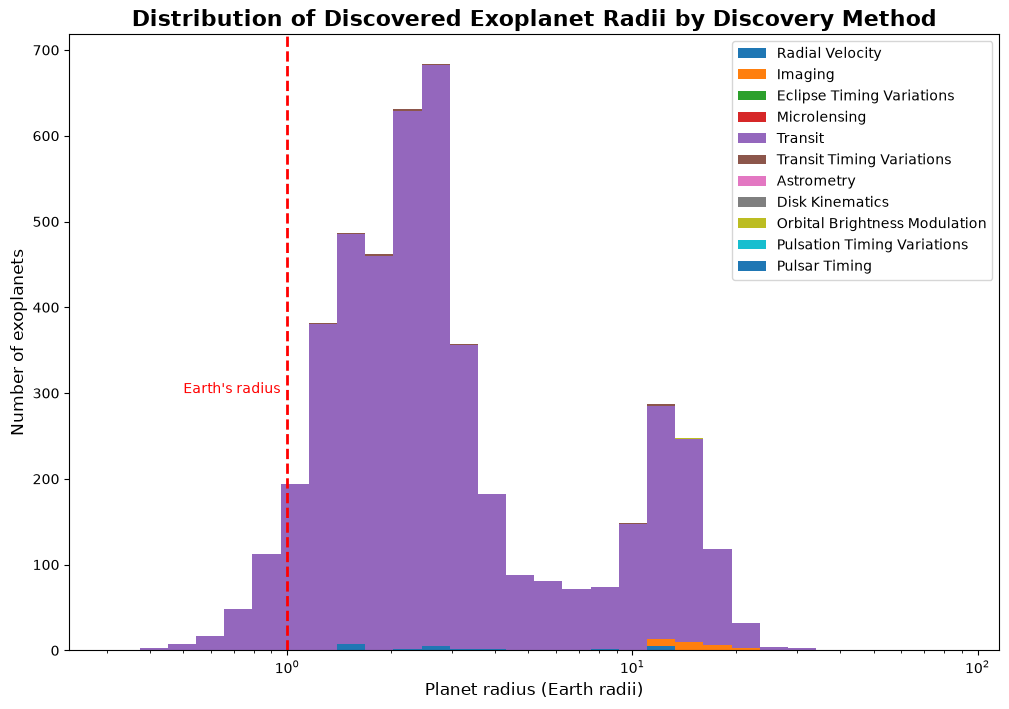

In [59]:
plot_data = []

methods = df_clean["discoverymethod"].dropna().unique()

for method in methods:
    radii = df_clean.loc[
        (df_clean["discoverymethod"] == method),
        "pl_rade"
        ].dropna()

    plot_data.append(radii)

bins = np.logspace(
        np.log10(df_clean["pl_rade"].min()),
        np.log10(df_clean["pl_rade"].max()),
        31
)

plt.figure(figsize = (12,8))

plt.hist(plot_data,
         bins = bins,
         stacked = True,
         label = methods)

plt.xscale("log")

plt.axvline(x = 1, color = "red", linewidth = 2, linestyle = "--")
plt.text(0.5, 300, "Earth's radius", color = "red")

plt.xlabel("Planet radius (Earth radii)", fontsize = 12)
plt.ylabel("Number of exoplanets", fontsize = 12)
plt.title("Distribution of Discovered Exoplanet Radii by Discovery Method", fontsize = 16, fontweight = "bold")
plt.legend()
plt.show()

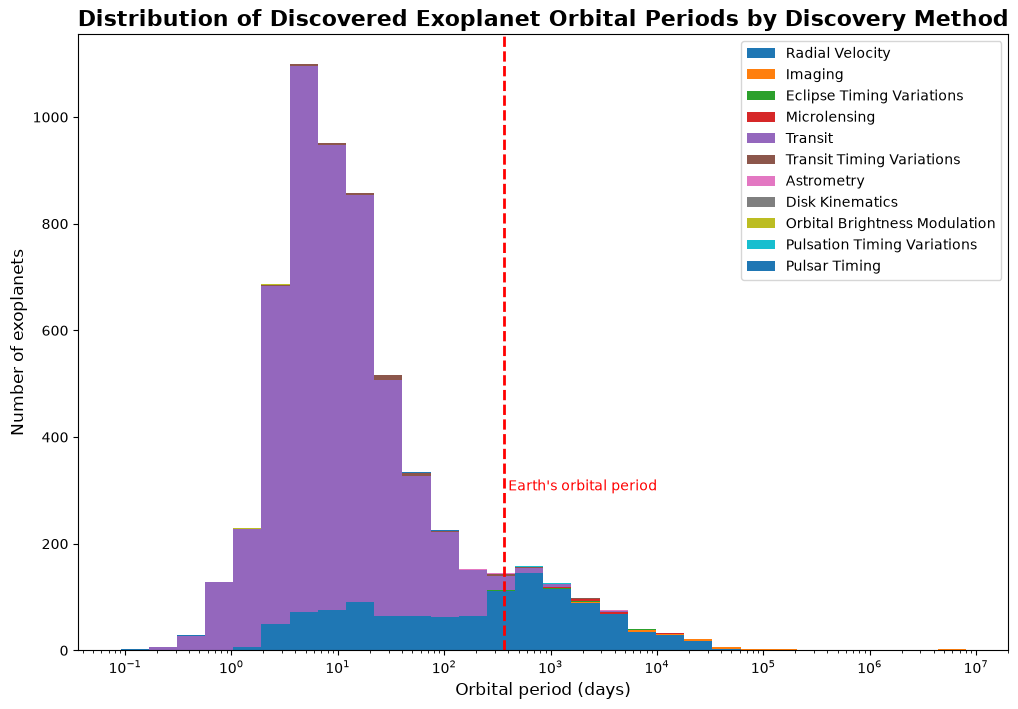

In [60]:
plot_data = []

methods = df_clean["discoverymethod"].dropna().unique()

for method in methods:
    periods = df_clean.loc[
        (df_clean["discoverymethod"] == method),
        "pl_orbper"
        ].dropna()

    plot_data.append(periods)

bins = np.logspace(
        np.log10(df_clean["pl_orbper"].min()),
        np.log10(df_clean["pl_orbper"].max()),
        31
)

plt.figure(figsize = (12,8))

plt.hist(plot_data,
         bins = bins,
         stacked = True,
         label = methods)

plt.xscale("log")

plt.axvline(x = 365.25, color = "red", linewidth = 2, linestyle = "--")
plt.text(400, 300, "Earth's orbital period", color = "red")

plt.xlabel("Orbital period (days)", fontsize = 12)
plt.ylabel("Number of exoplanets", fontsize = 12)
plt.title("Distribution of Discovered Exoplanet Orbital Periods by Discovery Method", fontsize = 16, fontweight = "bold")
plt.legend()
plt.show()

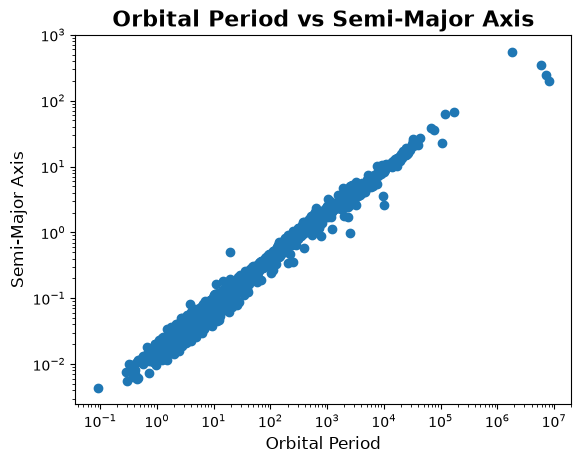

In [61]:
plt.scatter(df_clean["pl_orbper"], df_clean["pl_orbsmax"])

plt.xscale("log")
plt.yscale("log")

plt.title("Orbital Period vs Semi-Major Axis", fontsize = 16, fontweight = "bold")
plt.xlabel("Orbital Period", fontsize = 12)
plt.ylabel("Semi-Major Axis", fontsize = 12)
plt.show()

In [5]:
print(
    df_clean["pl_bmassprov"]
    .value_counts(dropna = False)
)

pl_bmassprov
NaN               3196
Mass              2143
Msini              950
Msin(i)/sin(i)       7
Name: count, dtype: int64


In [7]:
mass_radius["pl_bmassprov"].value_counts(dropna = False)

pl_bmassprov
Mass              1537
Msini                5
Msin(i)/sin(i)       2
Name: count, dtype: int64

In [10]:
mass_radius[
    mass_radius["pl_bmassprov"] != "Mass"
    ][
    ["pl_name", "hostname", "discoverymethod", "pl_bmasse",
     "pl_bmassprov", "pl_bmasseerr1", "pl_bmasseerr2",
     "pl_rade", "pl_radeerr1", "pl_radeerr2"]
    ].to_string(index = False)

'     pl_name   hostname discoverymethod  pl_bmasse   pl_bmassprov  pl_bmasseerr1  pl_bmasseerr2  pl_rade  pl_radeerr1  pl_radeerr2\n  GJ 414 A b   GJ 414 A Radial Velocity   7.600000          Msini       2.440000      -2.190000    2.630        1.220       -0.850\n  GJ 414 A c   GJ 414 A Radial Velocity  53.830000          Msini       9.180000      -8.580000    8.400        3.600       -2.500\n    K2-266 b     K2-266         Transit  11.267824 Msin(i)/sin(i)      11.371198     -11.371198    3.300        1.800       -1.300\n    K2-266 c     K2-266         Transit   0.290131 Msin(i)/sin(i)       0.170077      -0.170077    0.705        0.096       -0.085\nKepler-129 b Kepler-129         Transit  20.000000          Msini            NaN            NaN    2.400        0.040       -0.040\nKepler-139 d Kepler-139         Transit   4.658076          Msini       2.001763      -2.001763    1.695        0.061       -0.061\n TOI-1774.01   TOI-1774         Transit   8.500000          Msini       1.3

In [13]:
original_correlation = np.log10(mass_radius["pl_rade"]).corr(
    np.log10(mass_radius["pl_bmasse"])
)

mass_radius_filtered = mass_radius[mass_radius["pl_bmassprov"] == "Mass"].copy()

filtered_correlation = np.log10(mass_radius_filtered["pl_rade"]).corr(
    np.log10(mass_radius_filtered["pl_bmasse"])
)

print("Original number of planets:", len(mass_radius))
print("Filtered number of planets:", len(mass_radius_filtered))
print("Original logarithmic correlation:", original_correlation)
print("Filtered logarithmic correlation:", filtered_correlation)
print("Difference:", filtered_correlation - original_correlation)

Original number of planets: 1544
Filtered number of planets: 1537
Original logarithmic correlation: 0.862780477068796
Filtered logarithmic correlation: 0.8620220145853359
Difference: -0.0007584624834601206
